# TM-Scan case study — Slope 01

Complete TM-Scan workflow on one slope: point-cloud quality, traces and orientations,
circular sampling windows, scale effect, trace-length and size parameters, conditioned DFN,
spatial dependence and P32 maps.

Repository layout (this notebook is in `case_studies/slope_01/`):

```
TM_SCAN_Library_v0.1.0/       library source code and installable wheel (dist/)
case_studies/
    slope_01/
    slope_02/
    slope_article/
        case_study.ipynb      one notebook per case study
        database/
            mapped_planes/    one CSV of mapped planes (Dip, Dip_Dir, Nx, Ny, Nz, Joint_set, ...)
            slope_boundary/   boundary shapefile (closed 3D lines)
            surface_scan/     point cloud (x y z ...)
            traces/           one trace file per family (renamed with FAMILY_NAMES)
```

## 1. Installation
Installs the ready-made wheel, then restart the kernel. The second line replaces any older copy of tm-scan.

In [ ]:
%pip install ../../TM_SCAN_Library_v0.1.0/dist/tm_scan-0.1.0-py3-none-any.whl
%pip install --force-reinstall --no-deps ../../TM_SCAN_Library_v0.1.0/dist/tm_scan-0.1.0-py3-none-any.whl

In [1]:
%matplotlib inline
from pathlib import Path
import pandas as pd
import tm_scan as tm

tm.use_style()
print(f"tm-scan {tm.__version__}")

DATABASE = Path("database")                    # relative to this notebook
CASE_NAME = "Slope 01"
FAMILY_NAMES = {"j1_nodist": "F1", "j2_nodist": "F2"}   # trace file name -> family name ({} keeps the file names)
K_SMOOTH = 2.0                                 # voxel edge = k_smooth x mean point spacing
RADIUS = 6.0                                   # sampling-window radius (m)
SCALE_RADII = [3, 4, 5, 6, 7, 8]               # radii of the scale-effect study (m)
MU_RADII = [7, 8]                              # radii beyond the scale effect, for the representative mu (m)
ORIENTATION_MODEL = "spherical_kde"            # orientation law used in the DFN
DFN_CONFIG = tm.DFNConfig(half_size=18,        # 36 m cube edge = 3 x window diameter
                          realizations=30, seed=2026)
N_BOOT = 1000                                  # spatial bootstrap replicates

tm-scan 0.1.0


## 2. Read the database

In [2]:
data = tm.load_dataset(DATABASE).rename_families(FAMILY_NAMES)
data.name = CASE_NAME
planes = pd.read_csv(next((DATABASE / "mapped_planes").glob("*.csv")))

print(f"Point cloud: {len(data.scan):,} points")
print(f"Trace families: {list(data.traces)}")
print(f"Mapped planes per joint set:\n{planes.Joint_set.value_counts().to_string()}")

Point cloud: 714,384 points
Trace families: ['F1', 'F2']
Mapped planes per joint set:
Joint_set
F1           48
F2           48
Foliation    40


## 3. Point-cloud quality
Potential occlusions — gaps found on the 3D surface by the angle criterion (Bendels et al., 2006) and partial shadows of low point density — and the number of grid nodes produced by each `k_smooth`.

POINT CLOUD
  points                         : 714,384
  typical spacing                : 0.05012 m
  sampled surface (3D)           : 2715 m²
POTENTIAL OCCLUSIONS
  method                         : angle criterion (3D)
  surface in gaps                : 0.52 %  (15 gaps; largest 4.14 m²)
  points in partial shadow       : 0.15 %  (density < 25% of the median, 235 pts/m²)
GRID NODES BY k_smooth
  k = 1    voxel 0.5256 m  : 14,759 nodes
  k = 1.5  voxel 0.7884 m  : 6,816 nodes
  k = 2    voxel 1.051 m  : 3,718 nodes
  k = 3    voxel 1.577 m  : 1,743 nodes
  k = 4    voxel 2.102 m  : 1,010 nodes
  k = 6    voxel 3.153 m  : 436 nodes
  k = 8    voxel 4.205 m  : 251 nodes


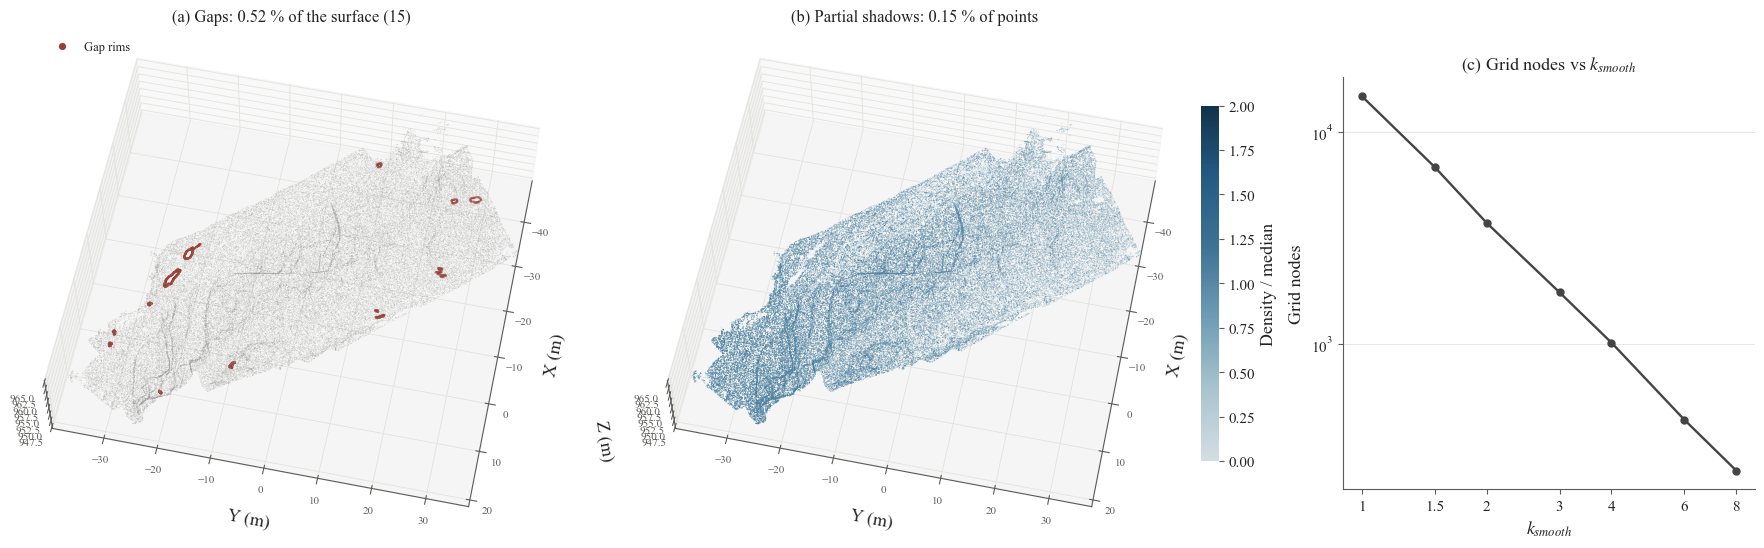

In [3]:
cloud = tm.describe_cloud(data)
print(cloud)
tm.plot_cloud(cloud);

## 4. Point cloud, traces and boundary

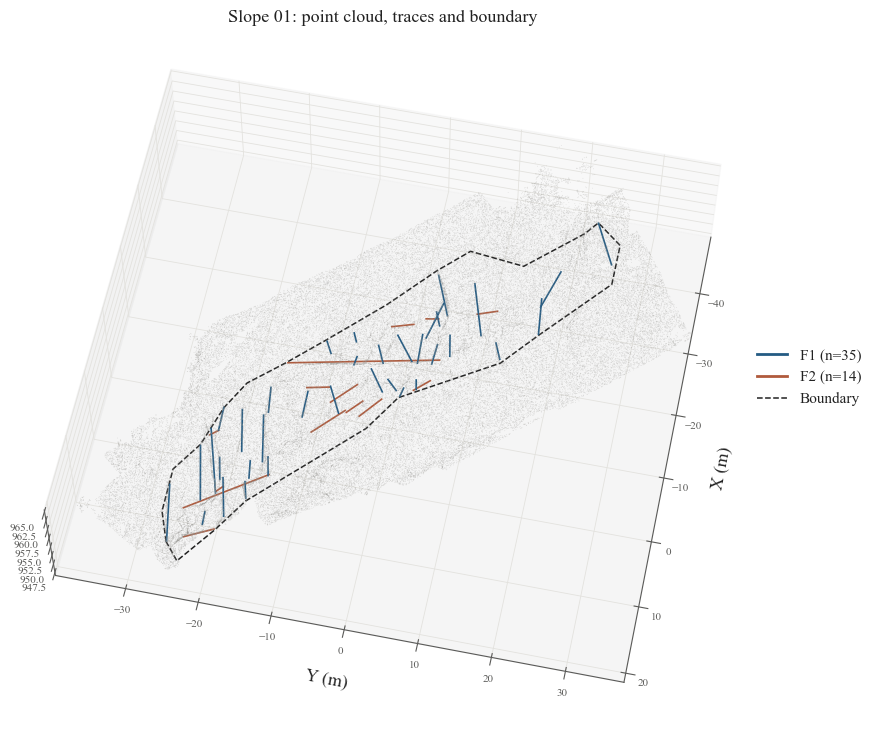

In [4]:
tm.plot_dataset(data);

## 5. General data and measured trace lengths

Points: 714,384 | extent X 70.9 m, Y 77.6 m, Z 18.9 m


,n_traces,mean,std,cov,min,max,best_fit,ks_pvalue
family,,,,,,,,
F1,35,4.243,2.009,0.473,1.462,8.888,lognormal,0.918
F2,14,5.975,6.186,1.035,2.438,23.434,lognormal,0.403


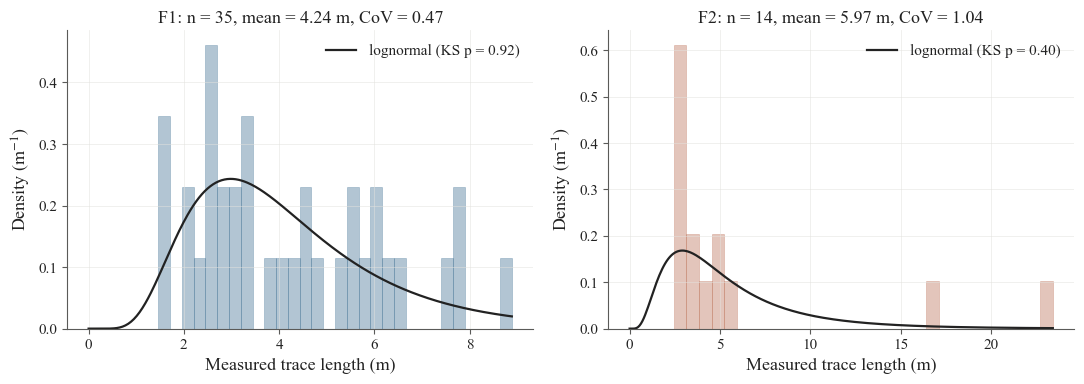

In [5]:
extent = data.scan.max() - data.scan.min()
print(f"Points: {len(data.scan):,} | extent X {extent.X:.1f} m, Y {extent.Y:.1f} m, Z {extent.Z:.1f} m")
display(tm.trace_length_summary(data).round(3))
tm.plot_trace_lengths(data);

## 6. Orientations
`split_planes` links each trace family to its `Joint_set` label in the mapped-planes CSV
(same name or same number, e.g. F1 ↔ j1) and prints the correspondence; pass
`mapping={"F1": "...", "F2": "..."}` to set it by hand. Poles come from the mapped normals (`Nx, Ny, Nz`).

Family <- Joint_set: F1 <- F1 (48 planes), F2 <- F2 (48 planes) | ignored: ['Foliation']


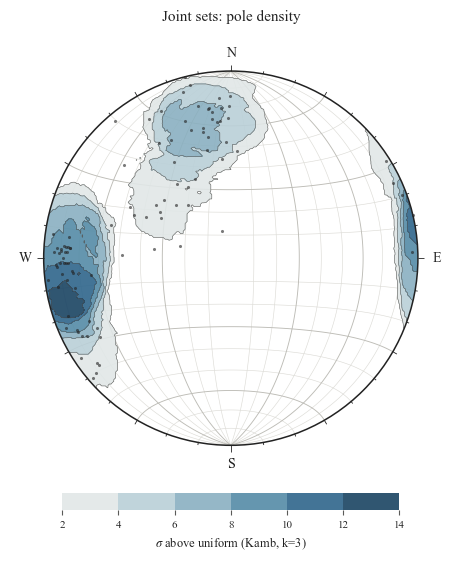

In [6]:
mapped = tm.split_planes(planes, data.traces)

#tm.plot_stereonet(dict(tuple(planes.groupby("Joint_set"))), kind="planes", title="All mapped planes");
tm.plot_stereonet(mapped, kind="contours", title="Joint sets: pole density");

,method,family,measured_planes,representative_dip,representative_dip_direction,kappa,beta,concentrations
0,fisher,F1,48,53.80,155.05,10.21,NaN,None
1,fisher,F2,48,79.82,78.97,26.41,NaN,None
2,kent,F1,48,52.83,154.07,14.85,5.28,None
3,kent,F2,48,79.88,78.16,51.71,19.88,None
4,bingham,F1,48,54.39,156.22,NaN,NaN,"(0.0, -4.2999675188797, -13.162013329250303)"
5,bingham,F2,48,79.78,79.33,NaN,NaN,"(0.0, -8.72169301106473, -45.130369468345265)"
6,spherical_kde,F1,48,54.39,156.22,41.03,NaN,None
7,spherical_kde,F2,48,79.78,79.33,184.25,NaN,None
8,empirical,F1,48,54.39,156.22,NaN,NaN,None
9,empirical,F2,48,79.78,79.33,NaN,NaN,None


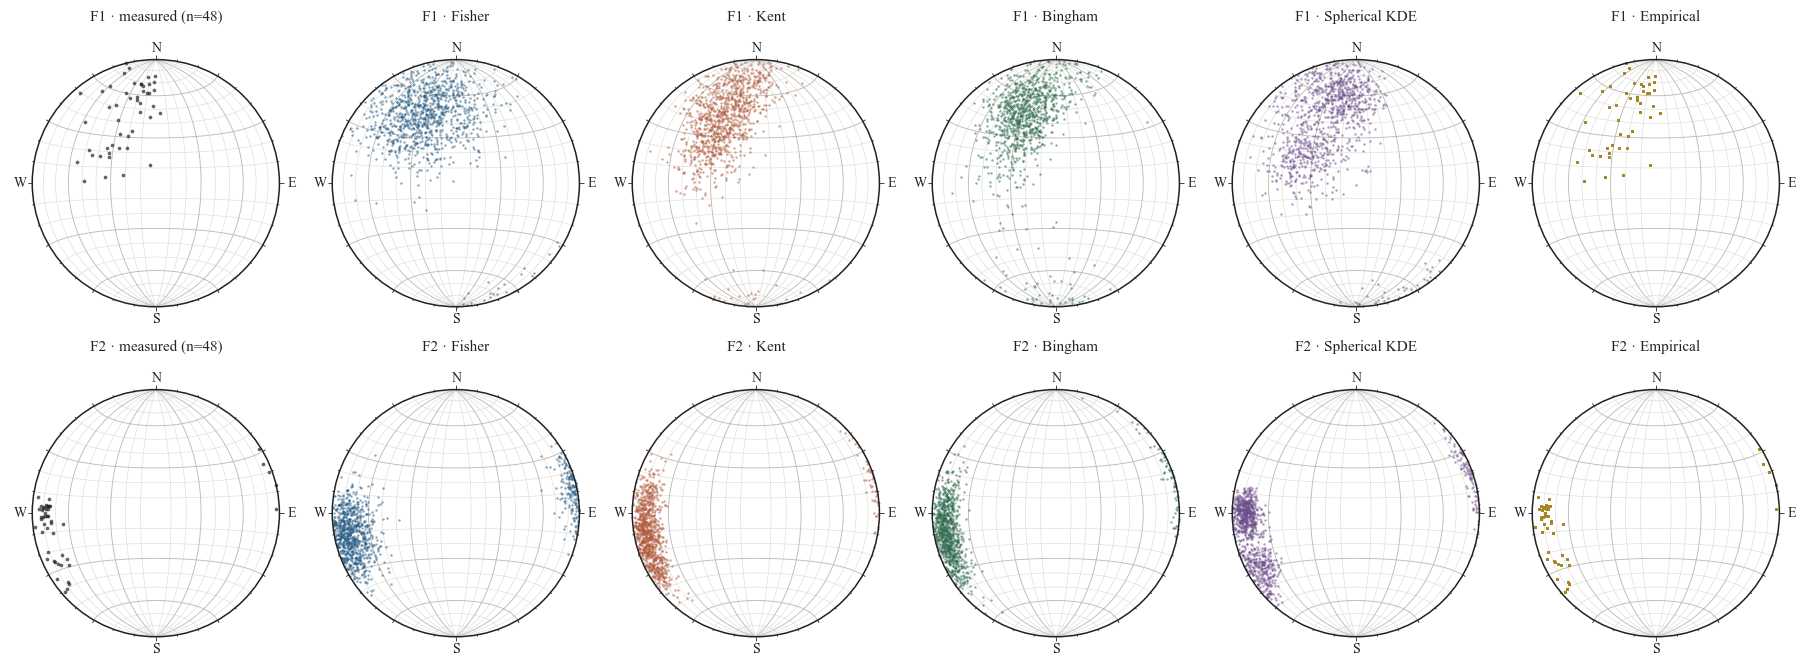

In [7]:
orientation = tm.compare_orientation_models(mapped)
display(orientation.summary.round(2))
orientation.plot();

## 7. TM-Scan with circular windows

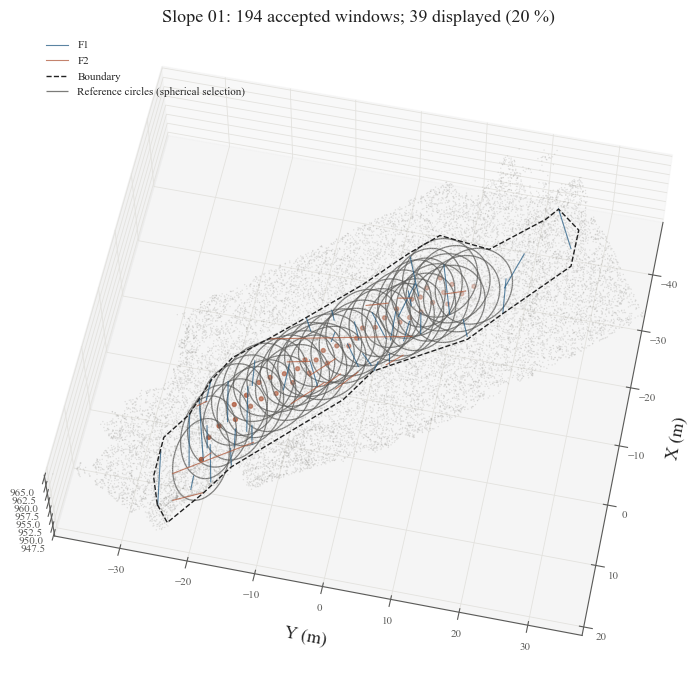

In [8]:
result = tm.analyze(data, tm.Window.sphere(RADIUS), sampling=tm.Sampling(k_smooth=K_SMOOTH))
tm.plot_windows(data, result, window_percent=20);           # percentage of windows drawn

## 7.1 Roughness of the sampling windows
Each window is flagged as admissible when the surface is planar at the window scale
(ρ = ξ_R / R ≤ 0.08) and at least 80 % of its area is covered by points. Windows are only
flagged here; none is removed. To exclude non-admissible windows from all later steps, run step 7
with `tm.analyze(..., roughness_filter=True)`.

,value
windows,194
radius,6.0
tau,0.08
min_cover,0.8
admissible_fraction,0.953608
median_rho,0.055822
A,0.078252
H,0.902911
R_min,0.796459
filter_applied,False


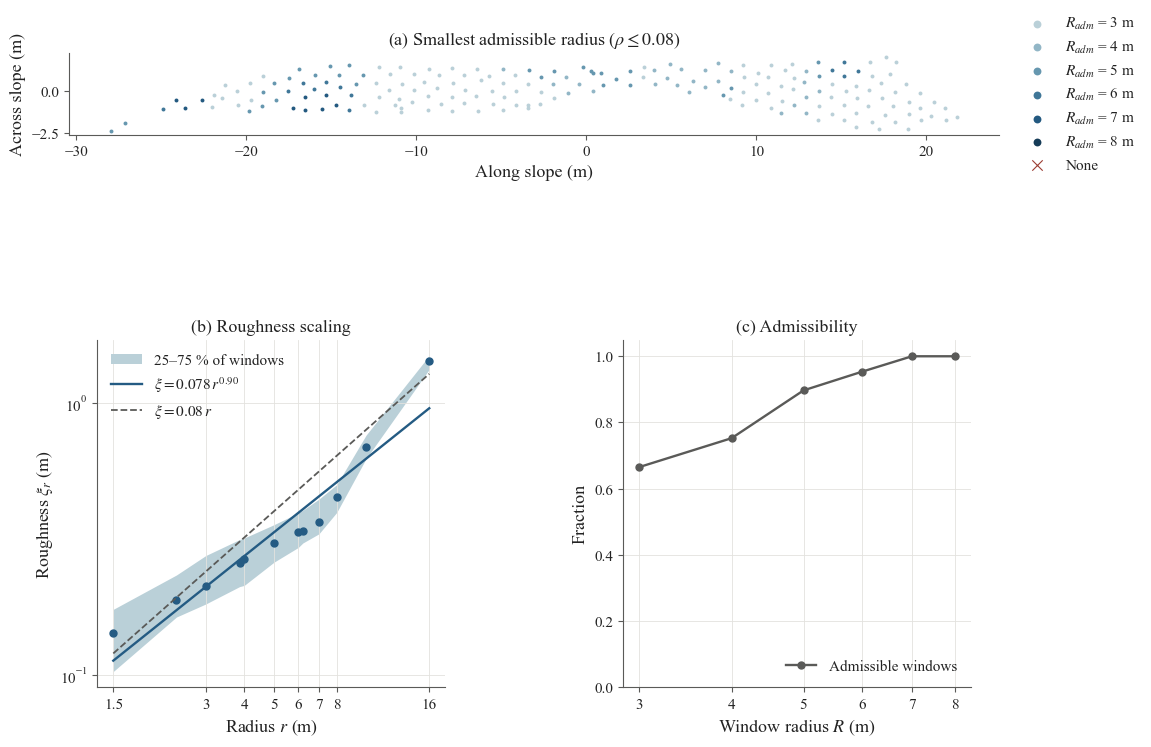

In [9]:
roughness = tm.assess_roughness(data, result, radii=SCALE_RADII)
display(roughness.summary().to_frame("value"))
roughness.plot();

## 8. Summary and scale effect

,family,final_windows,k_smooth,voxel_size,elapsed_seconds,P20_mean,P21_mean,mu_mean
0,F1,194,2.0,1.051,6.533,0.050,0.169,3.404
1,F2,194,2.0,1.051,6.533,0.026,0.097,6.283


Scale study: 6/6 | 7.1 s

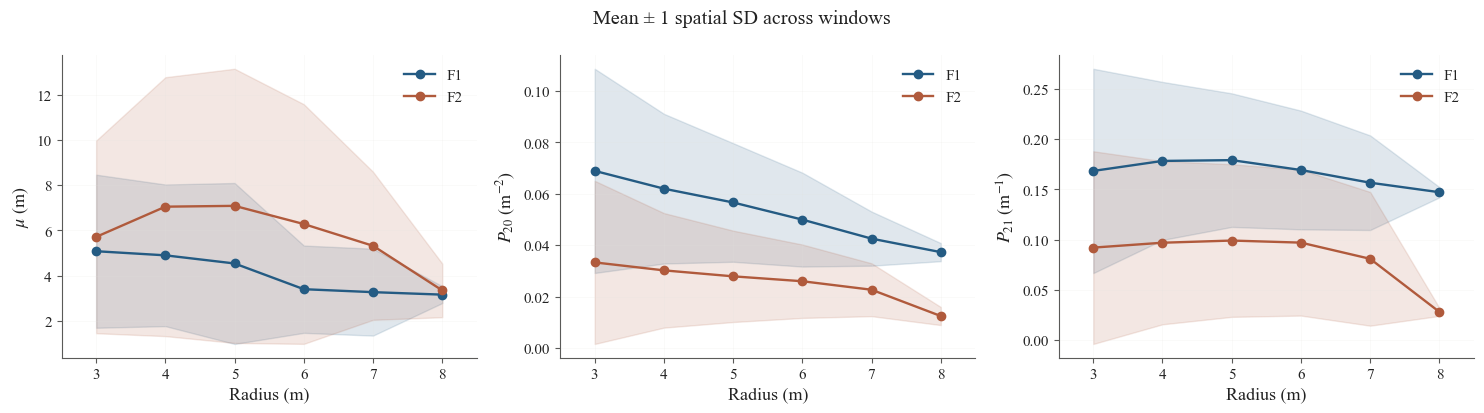

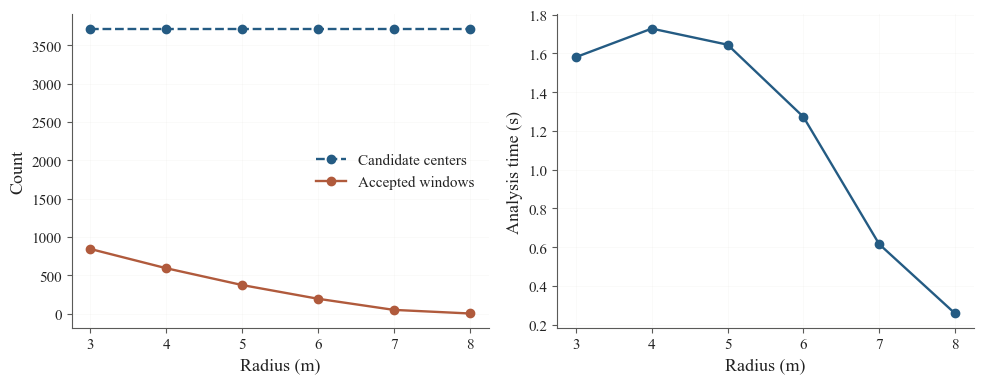

In [10]:
columns = ["family", "final_windows", "k_smooth", "voxel_size", "elapsed_seconds", "P20_mean", "P21_mean", "mu_mean"]
display(result.summary()[columns].round(3))

study = tm.radius_study(data, SCALE_RADII, sampling=tm.Sampling(k_smooth=K_SMOOTH))
tm.plot_study(study)
tm.plot_sampling(study);

## 9. Trace-length and size parameters
μ̄ is the mean window estimate of μ over `MU_RADII` (beyond the scale effect).
σ̄ = CoV × μ̄, with the unbiased CoV (ddof = 1) of all measured traces of the family.
μ_D and σ_D follow from the lognormal moment conversion; Dip, Dip-Dir and K come from the Fisher fit.

In [11]:
mu_bar = study.summary.query("radius in @MU_RADII").groupby("family").mu_mean.mean()
lengths = tm.statistics.build_segment_lengths(data.traces)[1]
fisher = orientation.summary.query("method == 'fisher'").set_index("family")

sizes = {family: tm.fit_from_mu(mu_bar[family], trace_lengths=lengths[family]) for family in data.traces}
parameter_table = pd.DataFrame({
    "mu_bar": mu_bar,
    "sigma_bar": {f: s.diagnostics["corrected_trace_std"] for f, s in sizes.items()},
    "form": "lognormal",
    "mu_D": {f: s.diameter_mean for f, s in sizes.items()},
    "sigma_D": {f: s.diameter_std for f, s in sizes.items()},
    "dip": fisher.representative_dip,
    "dip_dir": fisher.representative_dip_direction,
    "kappa_fisher": fisher.kappa,
}).loc[list(data.traces)]
display(parameter_table.round(2))

,mu_bar,sigma_bar,form,mu_D,sigma_D,dip,dip_dir,kappa_fisher
F1,3.22,1.52,lognormal,3.62,1.32,53.80,155.05,10.21
F2,4.34,4.49,lognormal,2.88,2.76,79.82,78.97,26.41


## 10. DFN simulations
Each window is reproduced in a 36 m cube and fractures are generated until the observed trace count (P20) is matched.

In [12]:
families = {family: tm.FractureFamily.from_distributions(orientation=orientation.fits[ORIENTATION_MODEL][family],
                                                         size=sizes[family])
            for family in data.traces}
simulation = tm.simulate_dfn(result, families, config=DFN_CONFIG)

DFN realizations: 11640/11640 | 8.4 s

## 11. DFN summary and an example realization

family,F1,F2
cases,1,1
windows,194,194
realizations_per_window,30,30
simulations,5820,5820
cube_edge,36,36
generation_volume,46656,46656
length_unit,m,m
boundary_treatment,clip: fracture area inside the cube,clip: fracture area inside the cube
diameter_min,0.0,0.0
diameter_max,inf,inf


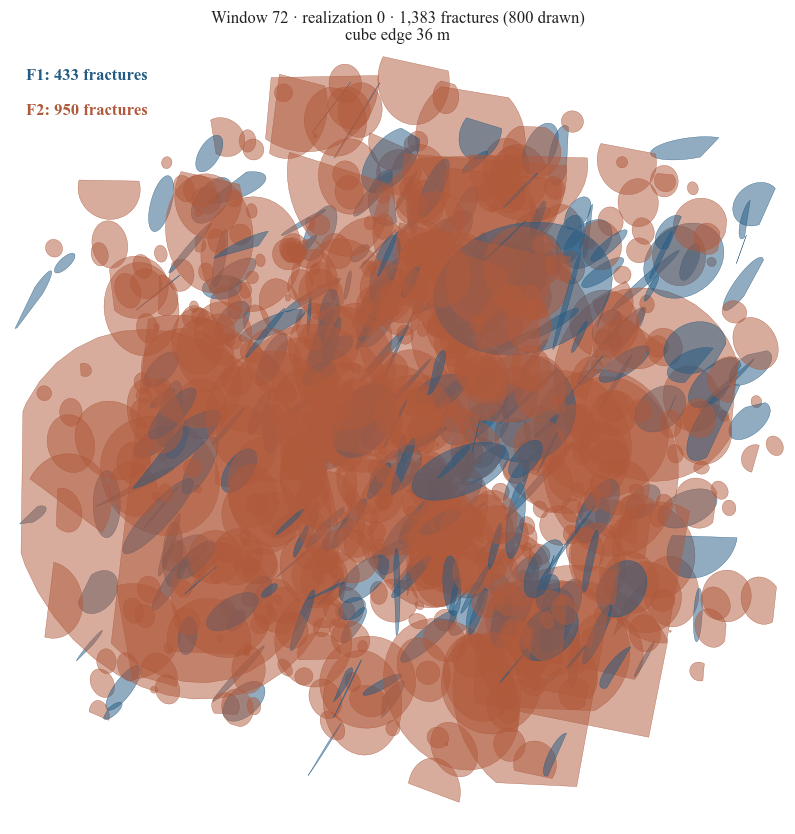

In [13]:
display(simulation.describe().T)

traces_per_window = simulation.summary.groupby("window_id").N_traces.sum().sort_values()
example = int(traces_per_window.index[len(traces_per_window) // 2])   # window with the median trace count
tm.plot_dfn(simulation, example);

## 12. Spatial dependence and spatial bootstrap
The correlogram compares the observed pair correlation with the part expected only from window
overlap. The bootstrap resamples blocks of edge 2R, so neighbouring windows stay together.

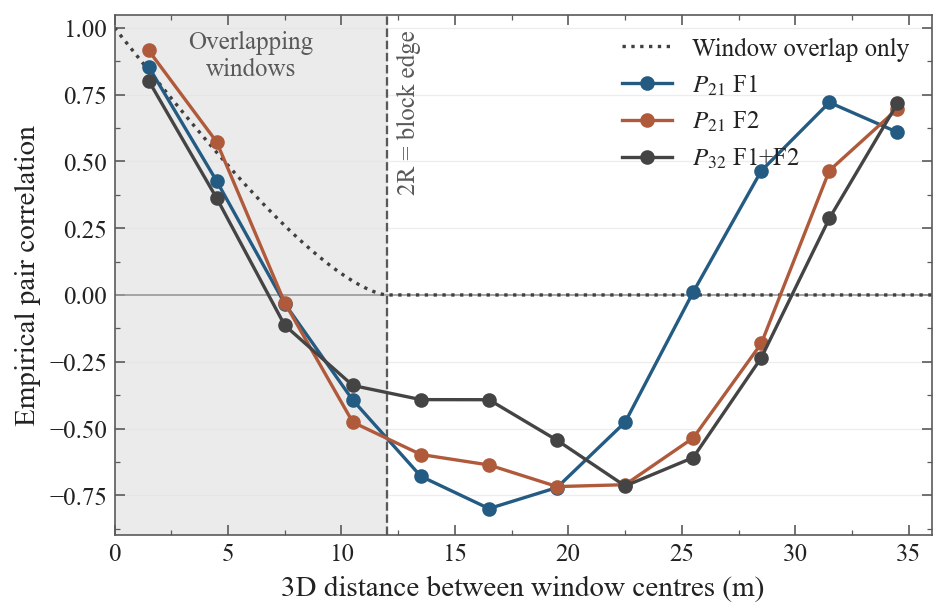

In [14]:
correlation = tm.spatial_correlation(result, simulation)
tm.plot_spatial_correlation(correlation);

,n_valid,mean,iid_se,spatial_se,spatial_relative_se_pct,se_inflation,n_eff,lower,upper,valid_replicates
metric,,,,,,,,,,
P20_F1,194,0.0500,0.0013,0.0047,9.4951,3.5947,15.0135,0.0422,0.0590,500
P21_F1,194,0.1693,0.0042,0.0177,10.4678,4.2115,10.9375,0.1385,0.2041,500
mu_F1,194,3.4036,0.1413,0.3389,9.9573,2.3978,33.7427,2.8216,4.1929,500
P20_F2,194,0.0260,0.0010,0.0043,16.5172,4.2309,10.8375,0.0169,0.0348,500
P21_F2,194,0.0971,0.0051,0.0240,24.7408,4.7058,8.7606,0.0506,0.1453,500
mu_F2,183,6.2828,0.3939,1.3265,21.1135,3.3675,16.1374,3.5749,8.8117,500
P32_F1,194,0.1229,0.0032,0.0114,9.2485,3.5212,15.6463,0.1041,0.1447,500
P32_F2,194,0.1091,0.0050,0.0225,20.6372,4.5258,9.4713,0.0645,0.1549,500
P32_Total,194,0.2320,0.0059,0.0230,9.9351,3.9210,12.6186,0.1829,0.2737,500


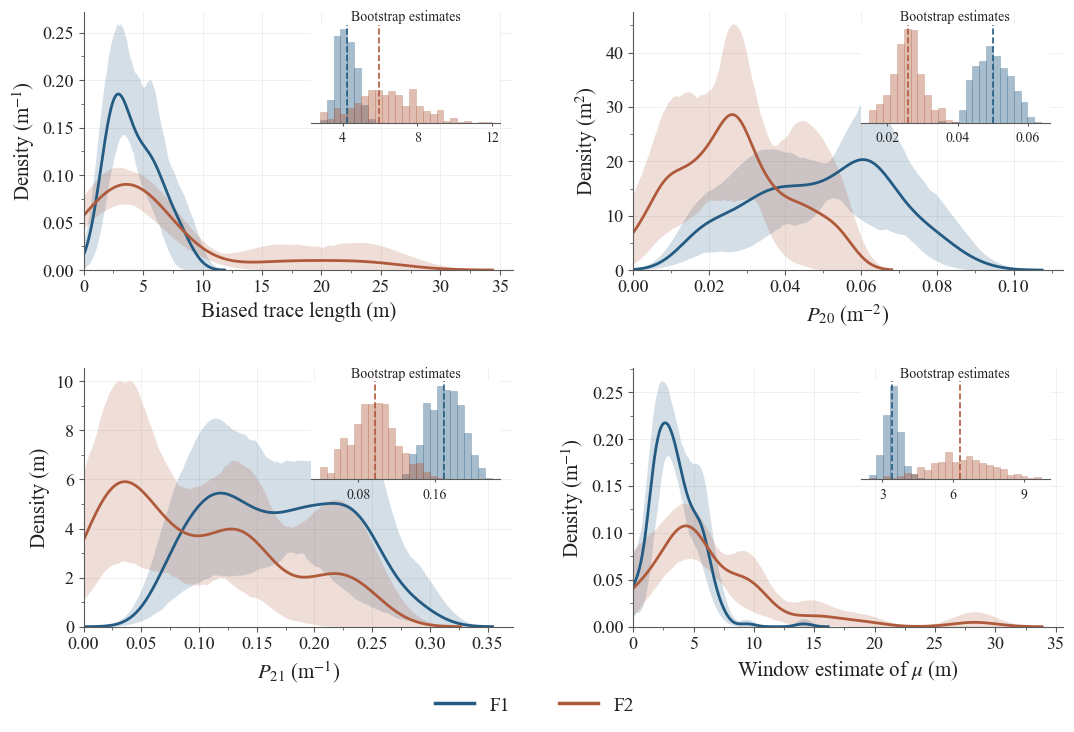

In [15]:
bootstrap = tm.spatial_bootstrap(result, simulation, dataset=data, n_boot=N_BOOT)
display(bootstrap.summary().round(4))
bootstrap.plot();

## 13. Empirical joint probability: P32 × P21
One mean P32 per window (average of its realizations).

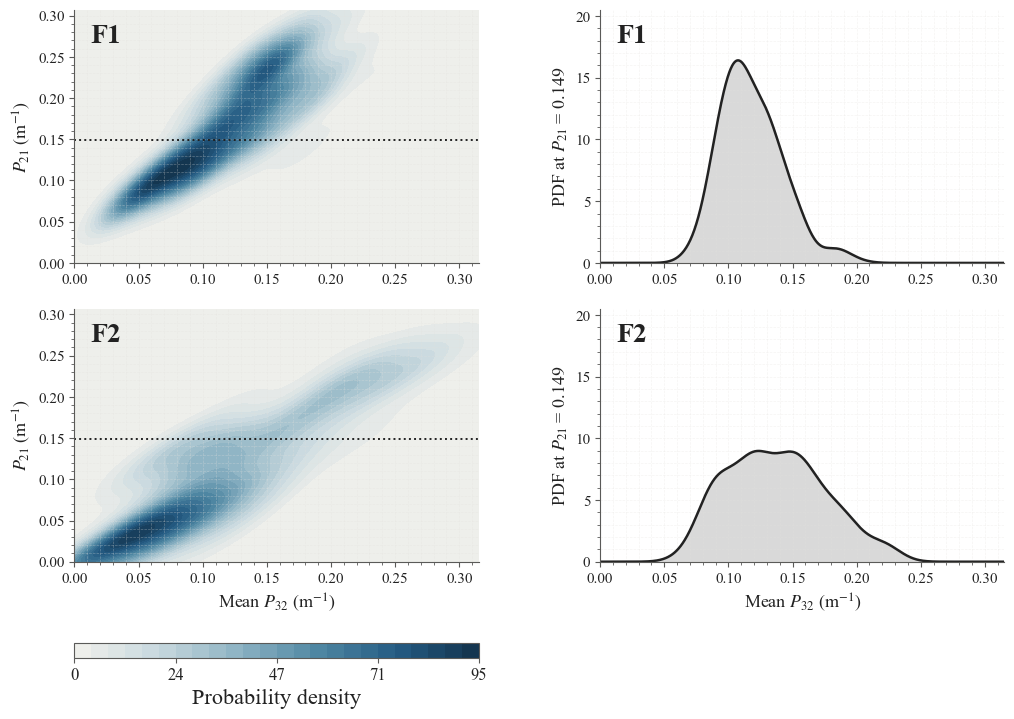

In [16]:
density = tm.fit_joint_density(simulation)
tm.plot_joint_density(density);

## 14. P32 map

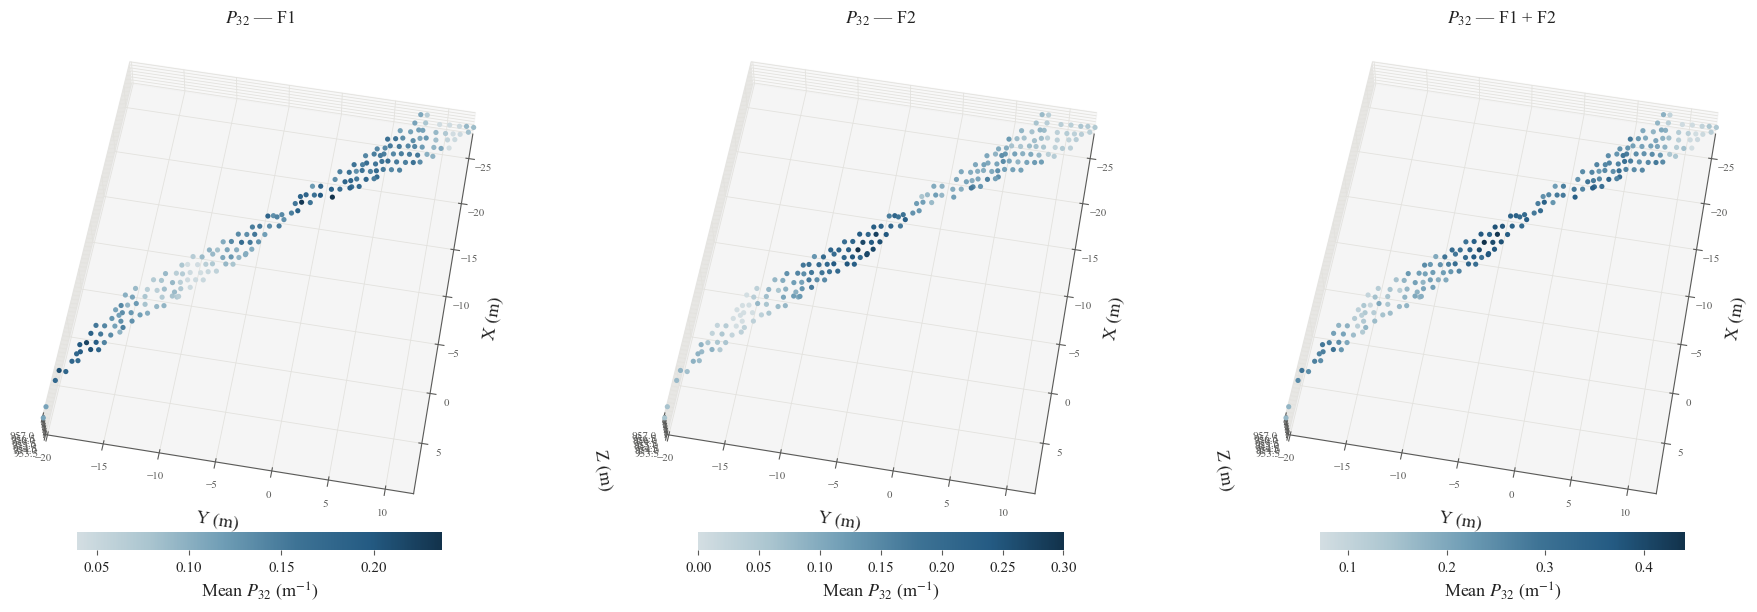

In [17]:
tm.plot_p32_map(simulation);

## 15. P32 uncertainty across DFN realizations

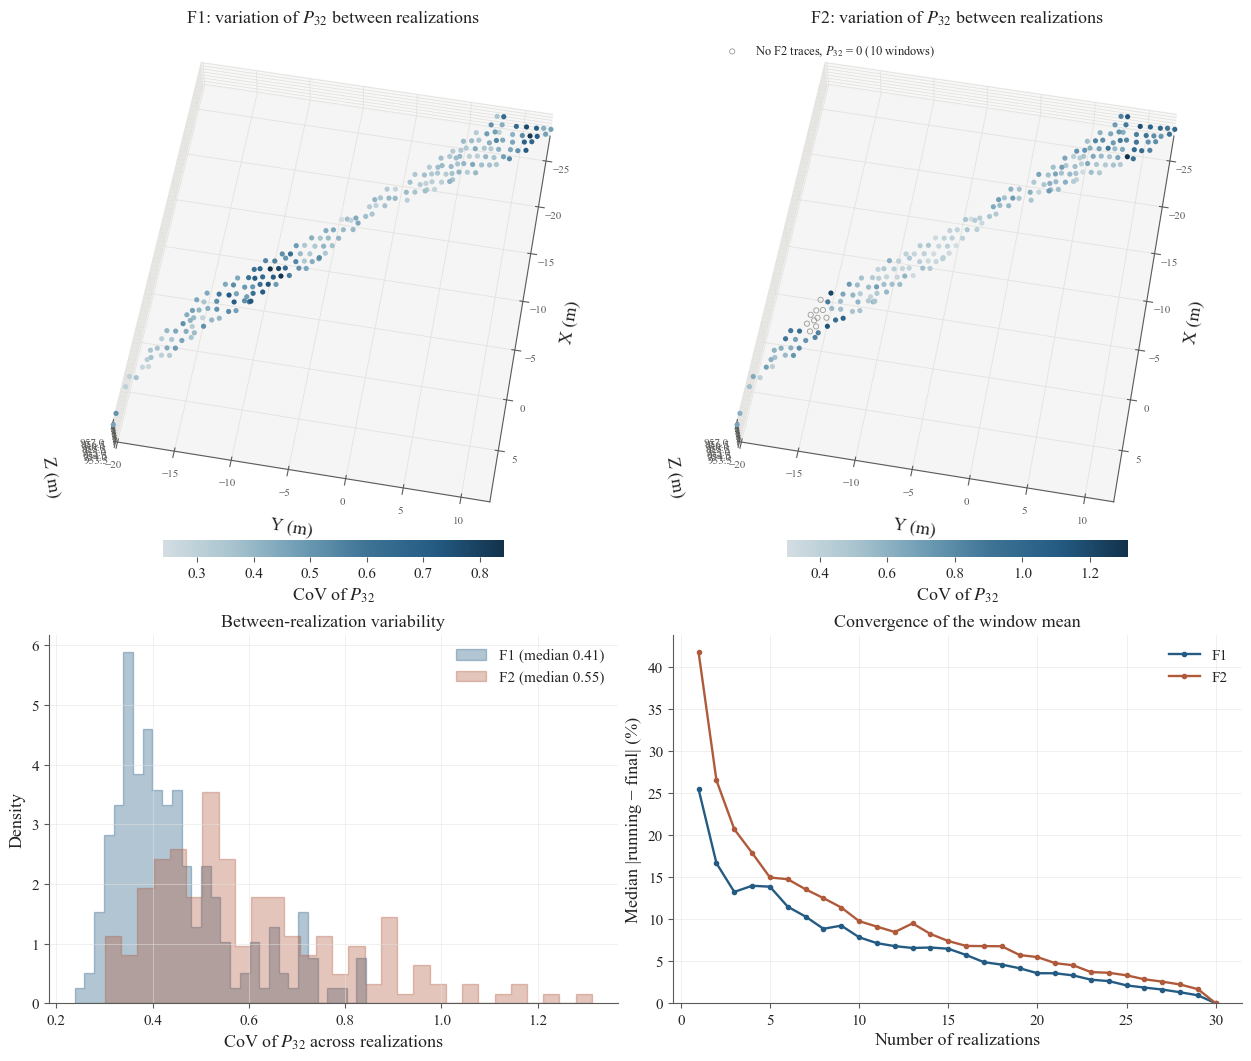

In [18]:
tm.plot_p32_uncertainty(simulation);